In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

%matplotlib inline

In [3]:
df_amazon = pd.read_csv('data/amz_uk_price_prediction_dataset.csv')
df_amazon.head()

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


Part 1: Analyzing Best-Seller Trends Across Product Categories
Objective: Understand the relationship between product categories and their best-seller status
Crosstab Analysis:

Create a crosstab between the product category and the isBestSeller status..

In [4]:
display (df_amazon)


,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers
...,...,...,...,...,...,...,...,...,...
2443646,2828589,B0CHSD7P2Q,"Motorbike Armour, Motorbike Clothing, Cycling ...",0.0,0,22.34,False,0,Motorbike Clothing
2443647,2828590,B0B7B8FNBQ,PROFIRST Waterproof Motorcycle 2 Piece Ladies ...,0.0,0,97.99,False,0,Motorbike Clothing
2443648,2828591,B0BD5FL5FB,Men’s Motorcycle Motorbike Biker Trousers Kevl...,0.0,0,52.99,False,0,Motorbike Clothing
2443649,2828592,B008OYLL4I,Texpeed Mens Motorcycle Motorbike Biker Trouse...,4.3,404,79.99,False,0,Motorbike Clothing


In [5]:
crosstab_result = pd.crosstab(df_amazon['category'], df_amazon['isBestSeller'])
crosstab_result

isBestSeller,False,True
category,,
3D Printers,247,1
3D Printing & Scanning,4065,2
Abrasive & Finishing Products,245,5
Action Cameras,1696,1
Adapters,251,3
...,...,...
Wind Instruments,243,7
Window Treatments,234,5
Women,17559,213


In [6]:
crosstab_result = pd.crosstab(df_amazon['category'], df_amazon['isBestSeller'])
crosstab_result['Total'] = crosstab_result.sum(axis=1)
crosstab_result['BestSeller %'] = (crosstab_result[True] / crosstab_result['Total']) * 100
crosstab_result

isBestSeller,False,True,Total,BestSeller %
category,,,,
3D Printers,247,1,248,0.403226
3D Printing & Scanning,4065,2,4067,0.049176
Abrasive & Finishing Products,245,5,250,2.000000
Action Cameras,1696,1,1697,0.058928
Adapters,251,3,254,1.181102
...,...,...,...,...
Wind Instruments,243,7,250,2.800000
Window Treatments,234,5,239,2.092050
Women,17559,213,17772,1.198515


In [7]:
crosstab_sorted = crosstab_result.sort_values(by='BestSeller %', ascending=False)
crosstab_sorted

isBestSeller,False,True,Total,BestSeller %
category,,,,
Grocery,9008,556,9564,5.813467
Smart Home Security & Lighting,98,6,104,5.769231
Health & Personal Care,9017,552,9569,5.768628
Mobile Phone Accessories,248,11,259,4.247104
Power & Hand Tools,8353,306,8659,3.533895
...,...,...,...,...
"CD, Disc & Tape Players",8798,0,8798,0.000000
General Music-Making Accessories,259,0,259,0.000000
Snowboard Boots,1449,0,1449,0.000000


Are there categories where being a best-seller is more prevalent? - Grocery, Smart HOme Security&Lighting, Health & Personal Care

2.Statistical Tests:
Conduct a Chi-square test to determine if the best-seller distribution is independent of the product category.

In [8]:
from scipy.stats import chi2_contingency
chi2_statistic, chi2_p_value, _, _ = chi2_contingency(crosstab_result)
chi2_statistic, chi2_p_value



(50784.635515685426, 0.0)

H0 = Best seller is independent of product category
H1 = Best seller is not independent of product category

Since the p value is < 0.05, we can reject the null  hypothesis suggesting that the best seller is not independent of the product category. 
The product category appears to have a significant effect on whether a product is a best-seller or not.

 Compute Cramérs V to understand the strength of association between best-seller status and category.

In [9]:
crosstab_result = pd.crosstab(df_amazon['category'], df_amazon['isBestSeller'])

In [10]:
from scipy.stats.contingency import association
association(crosstab_result, method="cramer")

0.1222829439760564

The product category has as significant effect on whether the porduct is a best-seller or not. However, Vramer' V =0.122 suggests a weak association between the two suggesting that category alone does not strongly predict whether a product becomes a best-seller.

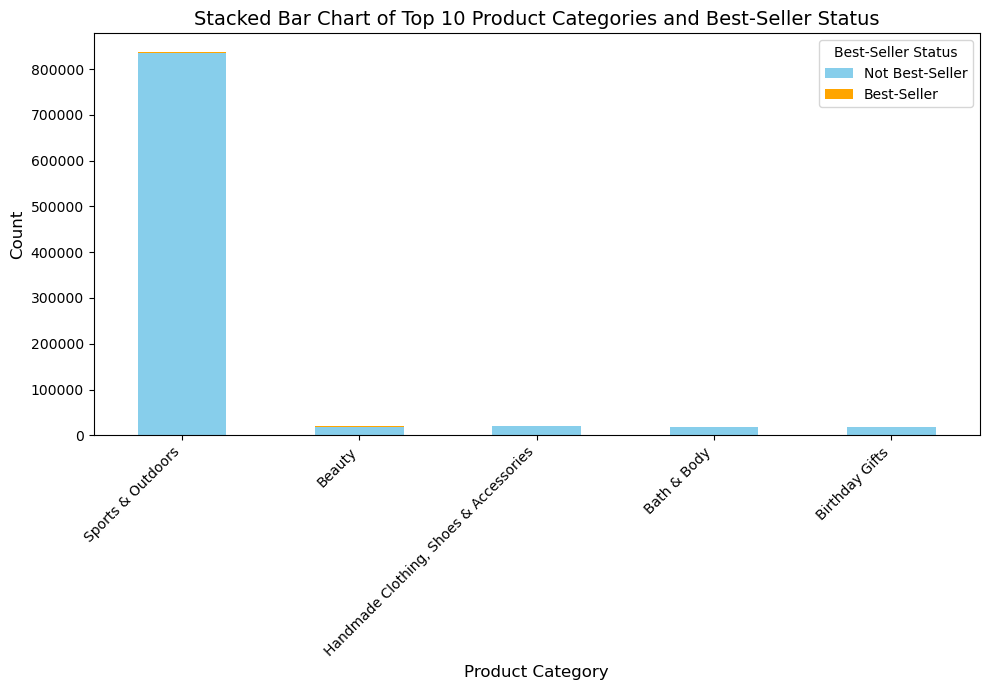

In [11]:
category_totals = crosstab_result.sum(axis=1).sort_values(ascending=False)

top_categories = category_totals.head(5).index

filtered_crosstab = crosstab_result.loc[top_categories]

filtered_crosstab.plot(kind='bar', stacked=True, figsize=(10, 7), color=['skyblue', 'orange'])

plt.title('Stacked Bar Chart of Top 10 Product Categories and Best-Seller Status', fontsize=14)
plt.xlabel('Product Category', fontsize=12)
plt.ylabel('Count', fontsize=12)
plt.xticks(rotation=45, ha='right')  
plt.legend(title='Best-Seller Status', labels=['Not Best-Seller', 'Best-Seller'])
plt.tight_layout()


Part 2: Exploring Product Prices and Ratings Across Categories and Brands

In [12]:
#Preliminary Step - Remove Outliers
Q1 = df_amazon['price'].quantile(0.25)
Q3 = df_amazon['price'].quantile(0.75)
IQR = Q3 - Q1

# Step 2: Define lower and upper bounds for outliers
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Step 3: Remove outliers
df_cleaned = df_amazon[(df_amazon['price'] >= lower_bound) & (df_amazon['price'] <= upper_bound)]

C:\Users\Nicole\AppData\Local\Temp\ipykernel_12304\529264261.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(x='category', y='price', data=df_top_20, inner="box", palette="Set3")


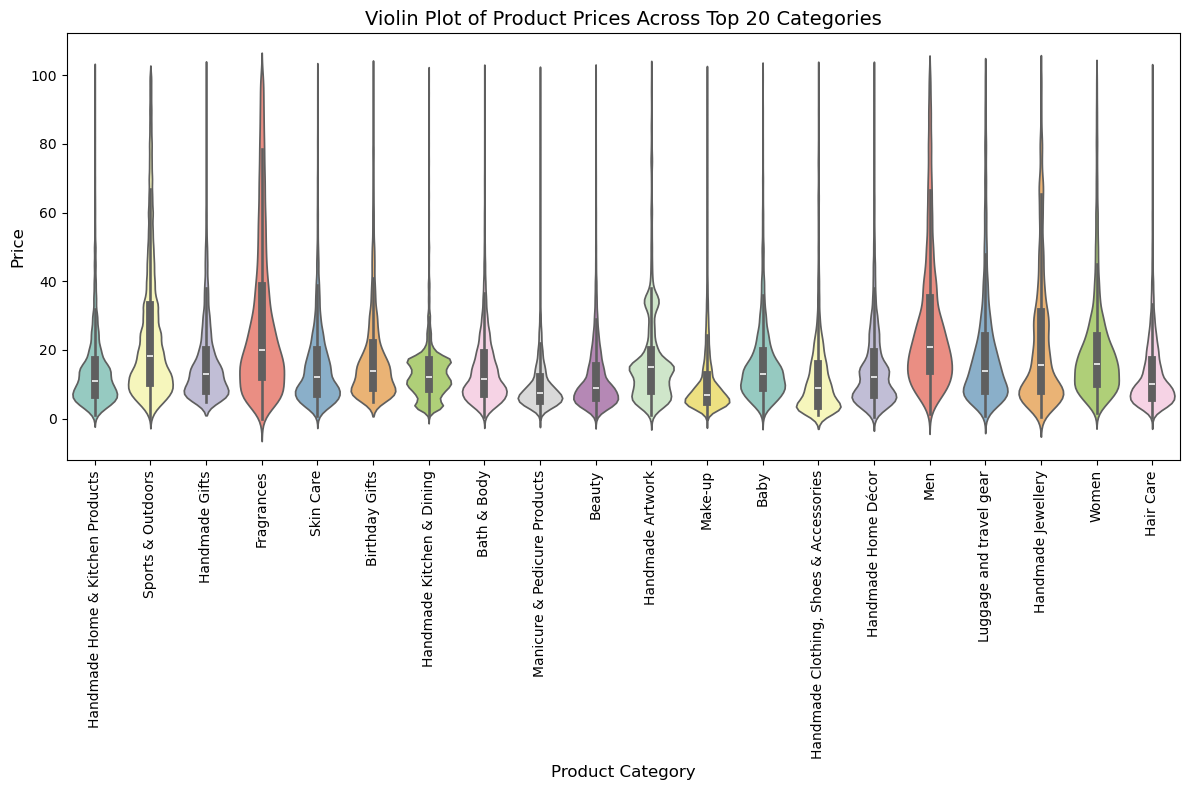

In [13]:
#Violin Plots
top_20_categories = df_cleaned['category'].value_counts().head(20).index
df_top_20 = df_cleaned[df_cleaned['category'].isin(top_20_categories)]

plt.figure(figsize=(12, 8))
sns.violinplot(x='category', y='price', data=df_top_20, inner="box", palette="Set3")
plt.xticks(rotation=90)
plt.title('Violin Plot of Product Prices Across Top 20 Categories', fontsize=14)
plt.xlabel('Product Category', fontsize=12)
plt.ylabel('Price', fontsize=12)
plt.tight_layout()
plt.show()

In [14]:
median_prices = df_cleaned.groupby('category')['price'].median().sort_values(ascending=False)
highest_median_category = median_prices.idxmax()
highest_median_price = median_prices.max()

print(f"The product category with the highest median price is: {highest_median_category} with a median price of {highest_median_price:}")

The product category with the highest median price is: Desktop PCs with a median price of 74.0


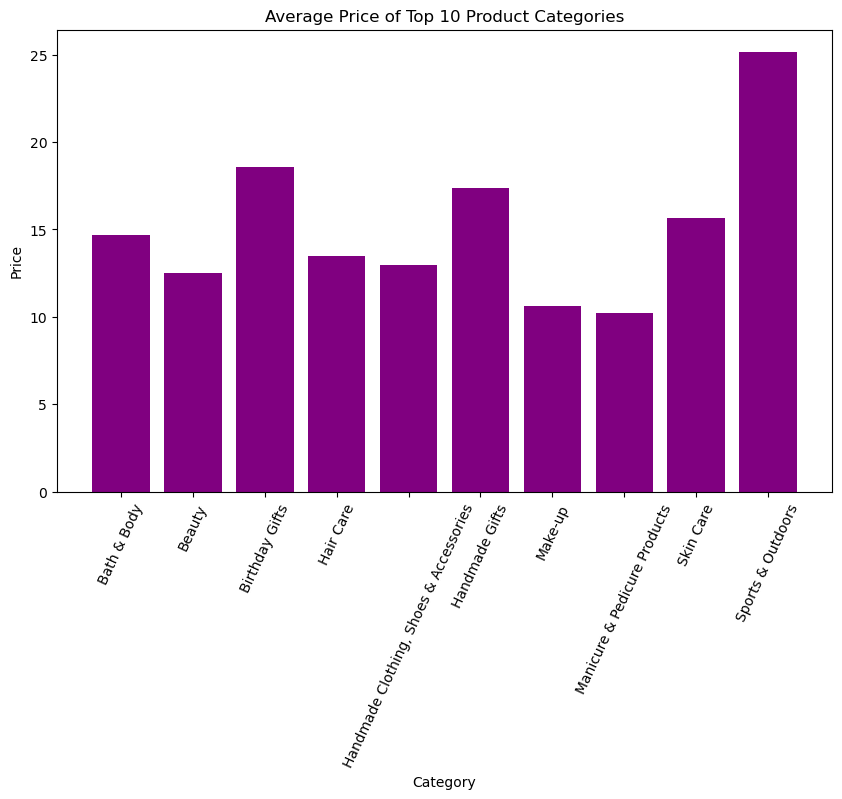

In [15]:
#2. Bar Charts
avg_prices = df_cleaned.groupby('category')['price'].mean().reset_index()

# Count the number of products in each category
category_counts = df_cleaned['category'].value_counts()

# Get top 10 categories based on count
top_categories = category_counts.head(10).index

# Filter average prices to only include top 10 categories
top_avg_prices = avg_prices[avg_prices['category'].isin(top_categories)]

# Plot
plt.figure(figsize=(10, 6))
plt.bar(top_avg_prices['category'], top_avg_prices['price'], color='purple')
plt.xlabel('Category')
plt.ylabel('Price')
plt.title('Average Price of Top 10 Product Categories')
plt.xticks(rotation=65)
plt.show()

C:\Users\Nicole\AppData\Local\Temp\ipykernel_12304\4268977483.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=top_df, x='category', y='stars', palette='Set2')


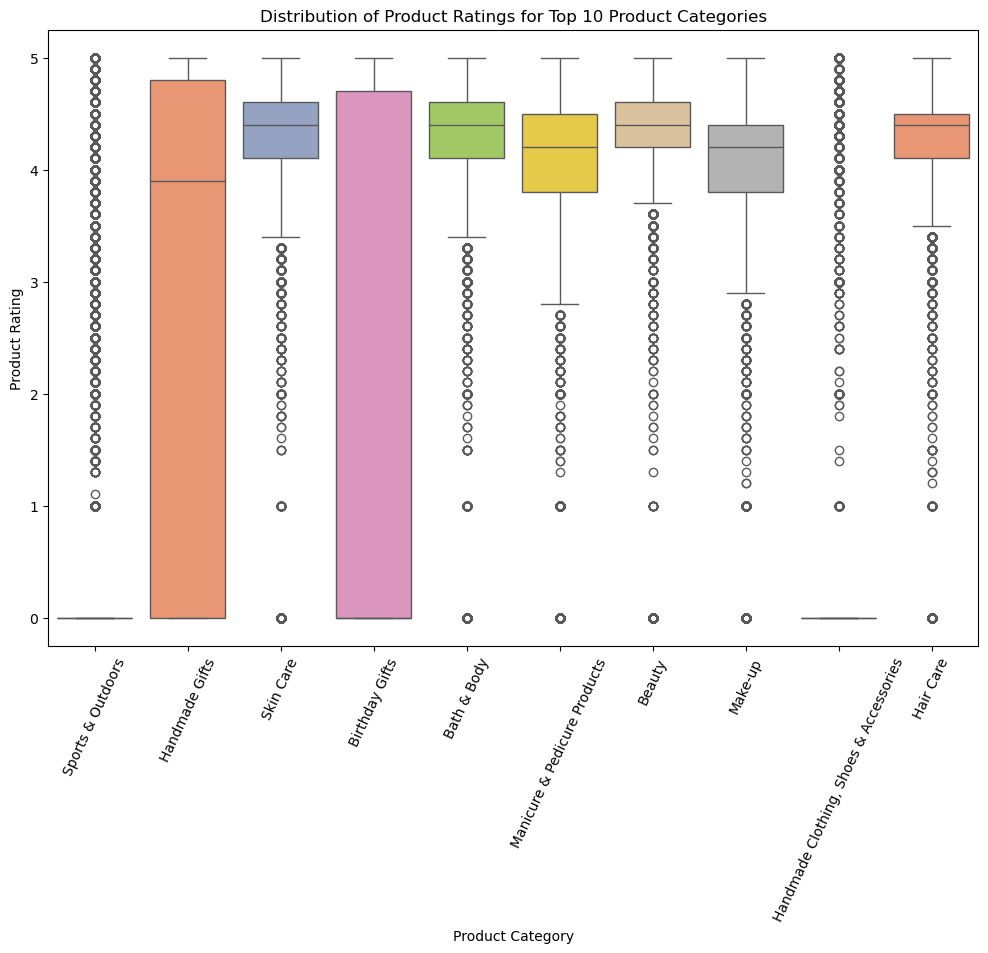

In [16]:
# 3 Box Plots
category_counts = df_cleaned['category'].value_counts()

# Get top 10 categories based on count
top_categories = category_counts.head(10).index

# Filter data to only include top 10 categories
top_df = df_cleaned[df_cleaned['category'].isin(top_categories)]

# Plot
plt.figure(figsize=(12, 8))
sns.boxplot(data=top_df, x='category', y='stars', palette='Set2')
plt.xlabel('Product Category')
plt.ylabel('Product Rating')
plt.title('Distribution of Product Ratings for Top 10 Product Categories')
plt.xticks(rotation=65)
plt.show()

In [17]:
def remove_outliers(df, column):
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)
    IQR = Q3 - Q1
    # Define bounds for outliers
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    # Filter out outliers
    return df[(df[column] >= lower_bound) & (df[column] <= upper_bound)]



In [18]:
median_ratings = df_amazon.groupby('category')['stars'].median().reset_index()
highest_median_category = median_ratings.loc[median_ratings['stars'].idxmax()]
print(f"Category with the highest median rating: {highest_median_category['category']} with a median rating of {highest_median_category['stars']}")

Category with the highest median rating: Computer Memory with a median rating of 4.7


Part 3: Investigating the Interplay Between Product Prices and Ratings
Objective: Analyze how product ratings (stars) correlate with product prices.

In [19]:
from scipy.stats import pearsonr
corr_coefficient, p_value = pearsonr(df_amazon['price'], df_amazon['stars'])

print(f"Pearson Correlation Coefficient: {corr_coefficient:.3f}")
print(f"P-value: {p_value:.3f}")

Pearson Correlation Coefficient: -0.125
P-value: 0.000


very weak negative correlation of -0.125 indicates that there is a slight tendency for higher-priced products to have lower ratings. 
very low p-value tells us that the observed correlation is statistically significant. 
hence, higher prices do not consistently lead to better or worse ratings in a meaningful way.

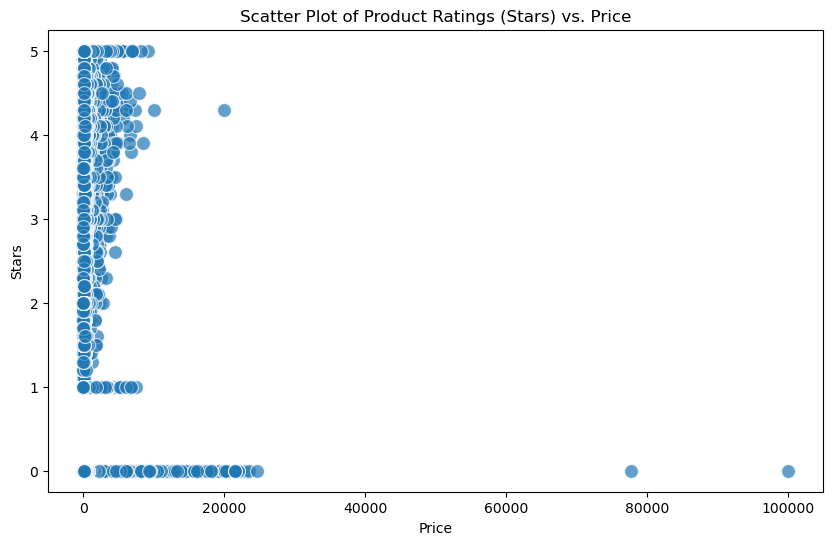

In [20]:
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df_amazon, x='price', y='stars', s=100, alpha=0.7)
plt.xlabel('Price')
plt.ylabel('Stars')
plt.title('Scatter Plot of Product Ratings (Stars) vs. Price')
plt.show()

In [21]:
numerical_columns = df_amazon.select_dtypes(include=['float64', 'int64'])
corr_matrix = numerical_columns.corr()
corr_matrix

,uid,stars,reviews,price,boughtInLastMonth
uid,1.000000,0.031696,0.019994,0.008273,0.016336
stars,0.031696,1.000000,0.085808,-0.124907,0.112536
reviews,0.019994,0.085808,1.000000,-0.013171,0.104043
price,0.008273,-0.124907,-0.013171,1.000000,-0.023439
boughtInLastMonth,0.016336,0.112536,0.104043,-0.023439,1.000000


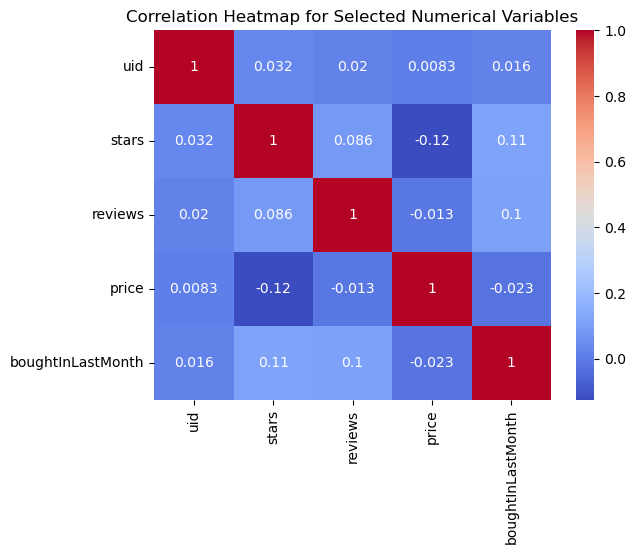

In [24]:
numerical_columns = df_amazon.select_dtypes(include=['float64', 'int64'])
corr_matrix = numerical_columns.corr()
corr_matrix

sns.heatmap(corr_matrix, annot=True, cmap="coolwarm")

plt.title("Correlation Heatmap for Selected Numerical Variables")
plt.show()

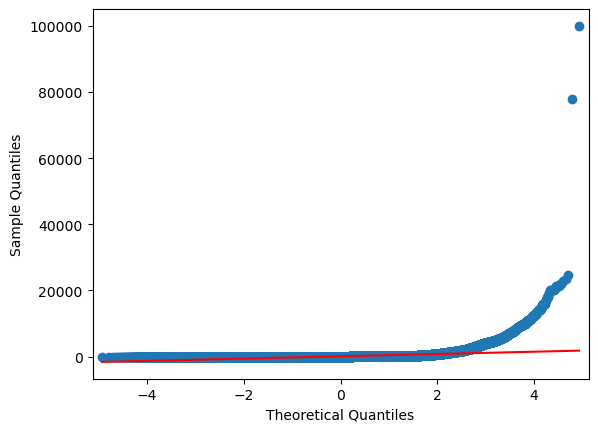

In [25]:
# QQ plot 
import statsmodels.api as sm
sm.qqplot(df_amazon['price'], line='s');

The data is not normally distributed and this is verified from the fact that there is a huge variation in the prices. 
Right skewed with outliers at 80,000 and 90,000.
